---
title: "Summary of Chapter 2: 10 arm testbed"
author: "Fabian"
date: "2026-01-10"
categories: ["Reinforcement Learning"]
image: thumbnail.png
format:
  html:
    code-fold: false
    toc: true
jupyter: python3
draft: False
---


### **Summary of Chapter 2: Multi-arm Bandits**

Notes based on the book Sutton, R. S., & Barto, A. G. (2018). Reinforcement learning: An introduction. MIT press.

This chapter focuses on the **evaluative** aspect of reinforcement learning in a simplified, non-associative setting (one state). The core problem is balancing **exploration** (gathering information) and **exploitation** (using current information to maximize reward).

**1. The -Armed Bandit Problem**
You are faced with  (or ) different actions (levers). Each action provides a reward drawn from a probability distribution specific to that action. The goal is to maximize the expected total reward over a time period.

* **Greedy Action:** The action with the highest estimated value. Selecting it is *exploitation*.
* 
**Nongreedy Action:** Selecting any other action is *exploration*, which improves estimates of nongreedy actions.



**2. Action-Value Methods**
We estimate the value of an action, , typically by averaging the rewards received so far for that action.

* **-Greedy Methods:** A greedy method always exploits. An -greedy method behaves greedily most of the time but selects a random action with small probability . This ensures all actions are sampled infinitely over time.



**3. Incremental Implementation**
To avoid storing all rewards, we update estimates incrementally using a step size. The general update rule is:


For stationary problems, the step size is  (sample average).

**4. Nonstationary Problems**
If the "true" values of actions change over time, we weight recent rewards more heavily by using a **constant step-size parameter** . This creates an exponential, recency-weighted average.

**5. Optimistic Initial Values**
Initializing action-value estimates to a high value (e.g., +5 when rewards are usually < 1) encourages early exploration. The agent is "disappointed" by initial rewards and switches actions rapidly until estimates converge.

**6. Upper-Confidence-Bound (UCB) Action Selection**
Instead of exploring randomly (like -greedy), UCB selects actions based on their potential to be optimal, considering both the estimate and the uncertainty:



The square root term represents variance/uncertainty. It decreases as an action is visited more.

**7. Gradient Bandit Algorithms**
Instead of estimating action *values*, these learn numerical *preferences* . Action probabilities are determined via a **softmax** distribution. Updates are performed using stochastic gradient ascent.

---

### **Python Implementation & Visualization**

This Python code implements the **10-armed bandit testbed** described in the book. It compares **-Greedy**, **Optimistic Initialization**, **UCB**, and **Gradient Bandit** algorithms.


Simulating 6 agents over 2000 runs of 1000 steps...


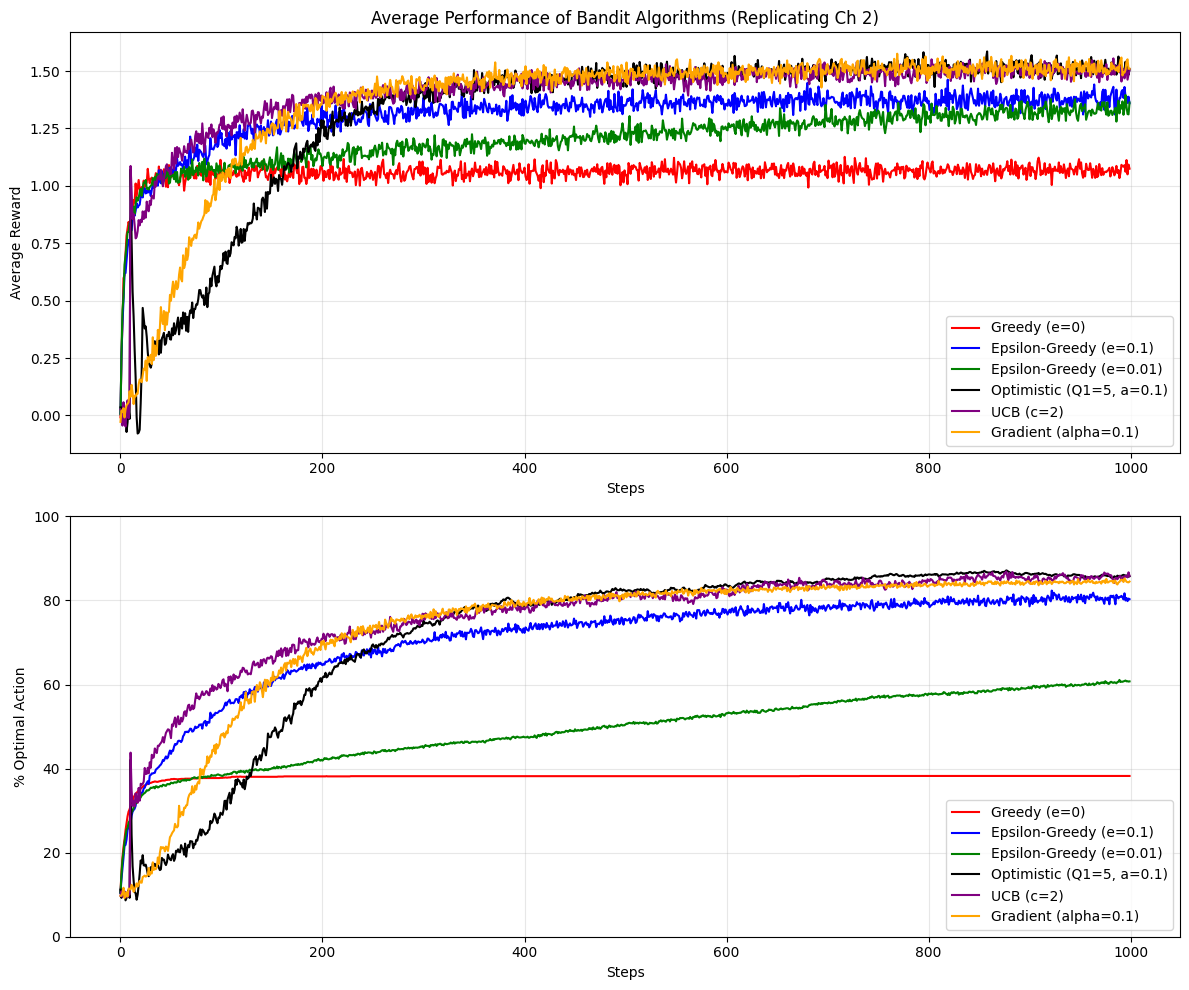

In [1]:
import numpy as np
import matplotlib.pyplot as plt

class BanditProblem:
    def __init__(self, k=10, true_mean=0, true_variance=1):
        # q*(a): True values of actions (normally distributed)
        self.q_true = np.random.normal(true_mean, true_variance, k)
        # Optimal action is the index of the max true value
        self.optimal_action = np.argmax(self.q_true)
        self.k = k

    def get_reward(self, action):
        # Reward is selected from a normal distribution around q*(a)
        # Rt ~ N(q*(a), 1) 
        return np.random.normal(self.q_true[action], 1)

class Agent:
    def __init__(self, k=10, epsilon=0, alpha=None, initial_value=0, 
                 ucb_c=None, gradient=False, gradient_baseline=True):
        self.k = k
        self.epsilon = epsilon
        self.alpha = alpha  # Step size
        self.ucb_c = ucb_c
        self.gradient = gradient
        self.gradient_baseline = gradient_baseline
        
        # Initialization
        if self.gradient:
            self.H = np.zeros(k) # Preferences [cite: 191]
            self.avg_reward = 0  # For baseline
            self.prob_actions = np.ones(k) / k
        else:
            self.q_est = np.full(k, float(initial_value)) # Qt(a) [cite: 166]
            self.action_counts = np.zeros(k) # Nt(a)
        
        self.time_step = 0

    def select_action(self):
        self.time_step += 1
        
        # 1. Gradient Bandit Selection [cite: 191]
        if self.gradient:
            exp_H = np.exp(self.H - np.max(self.H)) # Stability trick
            self.prob_actions = exp_H / np.sum(exp_H)
            return np.random.choice(self.k, p=self.prob_actions)

        # 2. UCB Selection 
        if self.ucb_c is not None:
            # Add small epsilon to avoid division by zero
            uncertainty = self.ucb_c * np.sqrt(np.log(self.time_step) / (self.action_counts + 1e-5))
            return np.argmax(self.q_est + uncertainty)

        # 3. Epsilon-Greedy Selection 
        if np.random.rand() < self.epsilon:
            return np.random.randint(self.k)
        else:
            # Break ties randomly for greedy actions
            max_val = np.max(self.q_est)
            candidates = np.where(self.q_est == max_val)[0]
            return np.random.choice(candidates)

    def update(self, action, reward):
        # 1. Gradient Update [cite: 192]
        if self.gradient:
            if self.gradient_baseline:
                self.avg_reward += (reward - self.avg_reward) / self.time_step
                baseline = self.avg_reward
            else:
                baseline = 0
            
            one_hot = np.zeros(self.k)
            one_hot[action] = 1
            
            # H_{t+1}(a) update
            # If a = At: H + alpha * (R - R_bar)(1 - pi)
            # If a != At: H - alpha * (R - R_bar)pi
            self.H += self.alpha * (reward - baseline) * (one_hot - self.prob_actions)
            return

        # 2. Action-Value Update
        self.action_counts[action] += 1
        
        # Determine step size: 1/n (sample average) or constant alpha
        step_size = 1.0 / self.action_counts[action] if self.alpha is None else self.alpha
        
        # Equation 2.3 / 2.5: NewEstimate <- OldEstimate + StepSize * Error [cite: 174, 177]
        self.q_est[action] += step_size * (reward - self.q_est[action])

# Simulation parameters
steps = 1000
runs = 2000  # Number of runs to average over (as per book figures) 

# Define agents to compare
configs = [
    {"label": "Greedy (e=0)", "eps": 0, "col": "red"},
    {"label": "Epsilon-Greedy (e=0.1)", "eps": 0.1, "col": "blue"},
    {"label": "Epsilon-Greedy (e=0.01)", "eps": 0.01, "col": "green"},
    {"label": "Optimistic (Q1=5, a=0.1)", "eps": 0, "alpha": 0.1, "init": 5.0, "col": "black"},
    {"label": "UCB (c=2)", "ucb": 2, "col": "purple"},
    {"label": "Gradient (alpha=0.1)", "grad": True, "alpha": 0.1, "col": "orange"}
]

avg_rewards = np.zeros((len(configs), steps))
optimal_actions = np.zeros((len(configs), steps))

print(f"Simulating {len(configs)} agents over {runs} runs of {steps} steps...")

for r in range(runs):
    bandit = BanditProblem()
    
    agents = []
    for c in configs:
        agents.append(Agent(
            epsilon=c.get("eps", 0),
            alpha=c.get("alpha", None),
            initial_value=c.get("init", 0),
            ucb_c=c.get("ucb", None),
            gradient=c.get("grad", False)
        ))

    for t in range(steps):
        for i, agent in enumerate(agents):
            act = agent.select_action()
            rew = bandit.get_reward(act)
            agent.update(act, rew)
            
            # Record stats
            avg_rewards[i, t] += rew
            if act == bandit.optimal_action:
                optimal_actions[i, t] += 1

# Normalize
avg_rewards /= runs
optimal_actions /= runs

# --- Plotting ---
plt.figure(figsize=(12, 10))

# Plot 1: Average Reward over Steps
plt.subplot(2, 1, 1)
for i, c in enumerate(configs):
    plt.plot(avg_rewards[i], label=c["label"], color=c["col"])
plt.xlabel("Steps")
plt.ylabel("Average Reward")
plt.title("Average Performance of Bandit Algorithms (Replicating Ch 2)")
plt.legend()
plt.grid(True, alpha=0.3)

# Plot 2: % Optimal Action over Steps
plt.subplot(2, 1, 2)
for i, c in enumerate(configs):
    plt.plot(optimal_actions[i] * 100, label=c["label"], color=c["col"])
plt.xlabel("Steps")
plt.ylabel("% Optimal Action")
plt.ylim(0, 100)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### **Concept Explanations in Code**

1. **Testbed:** The `BanditProblem` class simulates the environment. It generates true values `q_true` from a normal distribution and provides noisy rewards `get_reward`.


2. **Sample Average Rule:** In `Agent.update`, if `alpha` is None, we use `1.0 / self.action_counts[action]`. This implements .


3. **Exploration vs Exploitation:** The `select_action` method demonstrates the conflict. Epsilon-greedy forces random checks. UCB forces checks on actions with high variance (low visit counts).
4. **Recency Weighting:** When `alpha` is fixed (e.g., 0.1 in the Optimistic agent), the update becomes . This forgets old rewards exponentially, which is vital for non-stationary problems.